## Create a Mastersky from data downloaded directly form the archive

This notebook allows to create a mastersky using files from a different observation run which can then be used as fixed mastersky for a reduction

In [1]:

import pandas as pd
import numpy as np 
import os
from os.path import join, basename
import glob
from astropy.io import fits
from HCIutils import show_img
import SIRP

params = SIRP.Parameters()

In [2]:
# first read in all the files from a folder
input_dir = '/data/beegfs/astro-storage/groups/beuther/pasteimle/Background_data_ISPY'

DF = pd.DataFrame()

all_files = sorted(glob.glob(os.path.join(input_dir, '*.fits')))

for file in all_files:
    
    filename = basename(file)
    header = fits.getheader(file)

    exp_time = header['EXPTIME']
    obs_date = header['DATE-OBS'].split('T')[0]
    obs_time = header['DATE-OBS'].split('T')[1]
    object = header['OBJECT']

    if int(obs_time[:2]) < 14:
        obs_night = obs_date[:8] + str(int(obs_date[8:11])-1).zfill(2)  
    else: 
        obs_night = obs_date

    filter_name = header['HIERARCH ESO INS COMB IFLT']
    nd_filter = header['HIERARCH ESO INS4 FILT2 NAME']
    type = header['HIERARCH ESO DPR TYPE']


                
    DF_i = pd.DataFrame({'filename': [filename], 
                        'obs_night': [obs_night],
                        'obs_run': [obs_night[:-3]],
                        'filter': [filter_name],
                        'type': [type],
                        'object': [object],
                        'exp_time': [exp_time], 
                        'filepath': [file],
                        'nd_filter': [nd_filter]
                        })

    DF = pd.concat((DF, DF_i), ignore_index=True)        


In [3]:
DARK_DF = DF[DF['type'] == 'DARK']
DARK_DF 

,filename,obs_night,obs_run,filter,type,object,exp_time,filepath,nd_filter
0,SPHER.2022-04-03T10:18:15.692.fits,2022-04-02,2022-04,DB_Y23,DARK,DARK,8.000000,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
4,SPHER.2022-04-04T10:23:43.496.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,0.837464,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
5,SPHER.2022-04-04T10:24:03.957.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,1.000000,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
6,SPHER.2022-04-04T10:24:26.242.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,2.000000,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
7,SPHER.2022-04-04T10:24:59.332.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,3.000000,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
8,SPHER.2022-04-04T10:25:42.667.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,4.000000,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
9,SPHER.2022-04-04T10:26:34.775.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,5.000000,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
10,SPHER.2022-04-04T10:33:23.997.fits,2022-04-03,2022-04,DB_NDH23,DARK,DARK,5.000000,/data/beegfs/astro-storage/groups/beuther/past...,OPEN
16,SPHER.2022-04-04T11:05:47.278.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,0.837464,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5
17,SPHER.2022-04-04T11:06:07.725.fits,2022-04-03,2022-04,DB_Y23,DARK,DARK,1.000000,/data/beegfs/astro-storage/groups/beuther/past...,ND_3.5


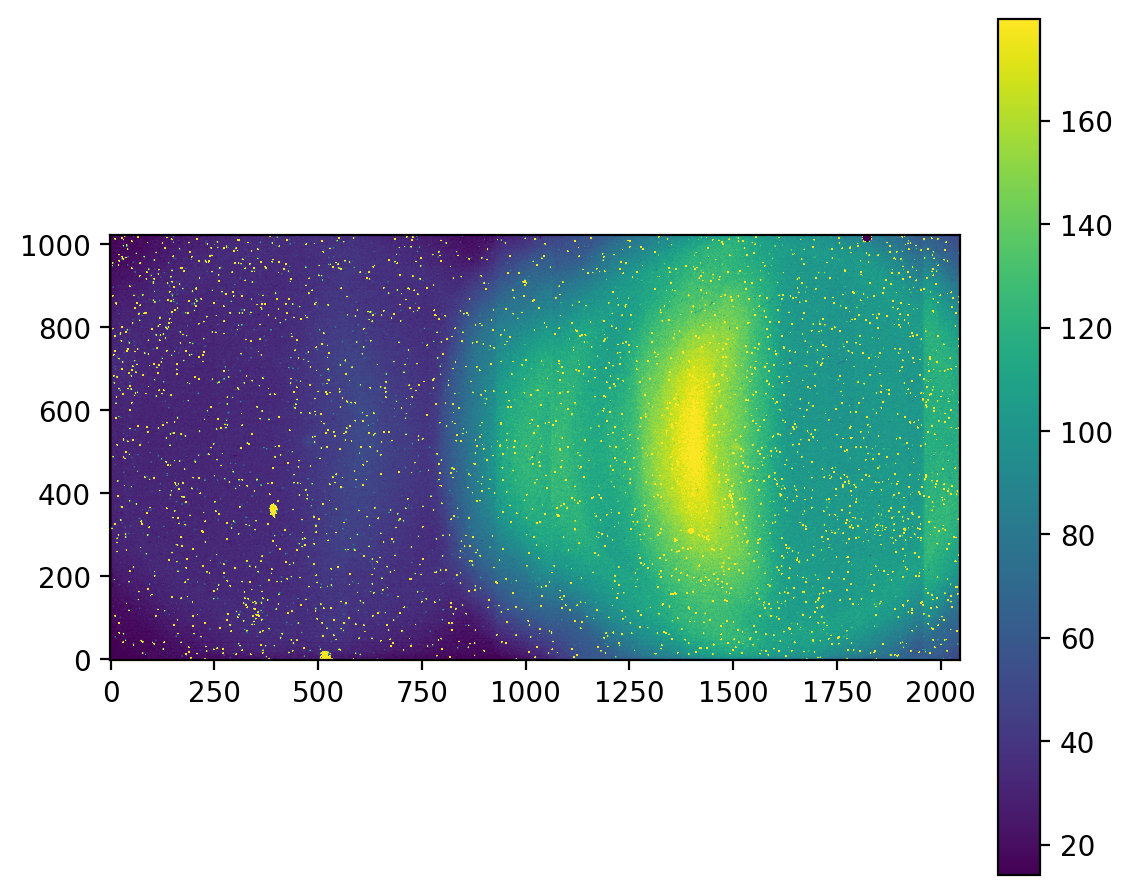

In [4]:
show_img(fits.getdata(DF.loc[3, 'filepath'])[0])

In [9]:
input_dir = '/data/beegfs/astro-storage/groups/beuther/pasteimle/Background_data_ISPY_proc'

L_or_R = 'right'
all_sky_files = glob.glob(os.path.join(input_dir, 'HIP59747/IRDIS/2022-04-03/DB_K12/stage2/{}*.fits'.format(L_or_R.upper())))

In [10]:
master_sky_folder = os.path.join(input_dir, 'master_sky_files')
if not os.path.exists(master_sky_folder):
    os.makedirs(master_sky_folder)
master_sky_filepath = os.path.join(master_sky_folder, 'master_sky_{}_{}.fits'.format('HD101412', L_or_R))

SIRP.routines.make_mastersky(all_sky_files, master_sky_filepath, True)

In [11]:
print(master_sky_filepath)

/data/beegfs/astro-storage/groups/beuther/pasteimle/Background_data_ISPY_proc/master_sky_files/master_sky_HD101412_right.fits
